# SECTION 1. Introduction to the Problem, Task, and Dataset

Vector-borne diseases (VBDs) like dengue, chikungunya, malaria, and the Zika virus have remained a considerable public health concern in tropical and subtropical regions. These diseases are mainly transmitted by vectors such as mosquitoes and ticks and have various overlapping symptoms, including fever, rash, joint pain, and nausea.

Due to the similarity in symptoms, diagnosis remains a challenge.

This project aims to address this particular problem by designing machine learning models that can classify VBDs

# SECTION 2. Description of the dataset


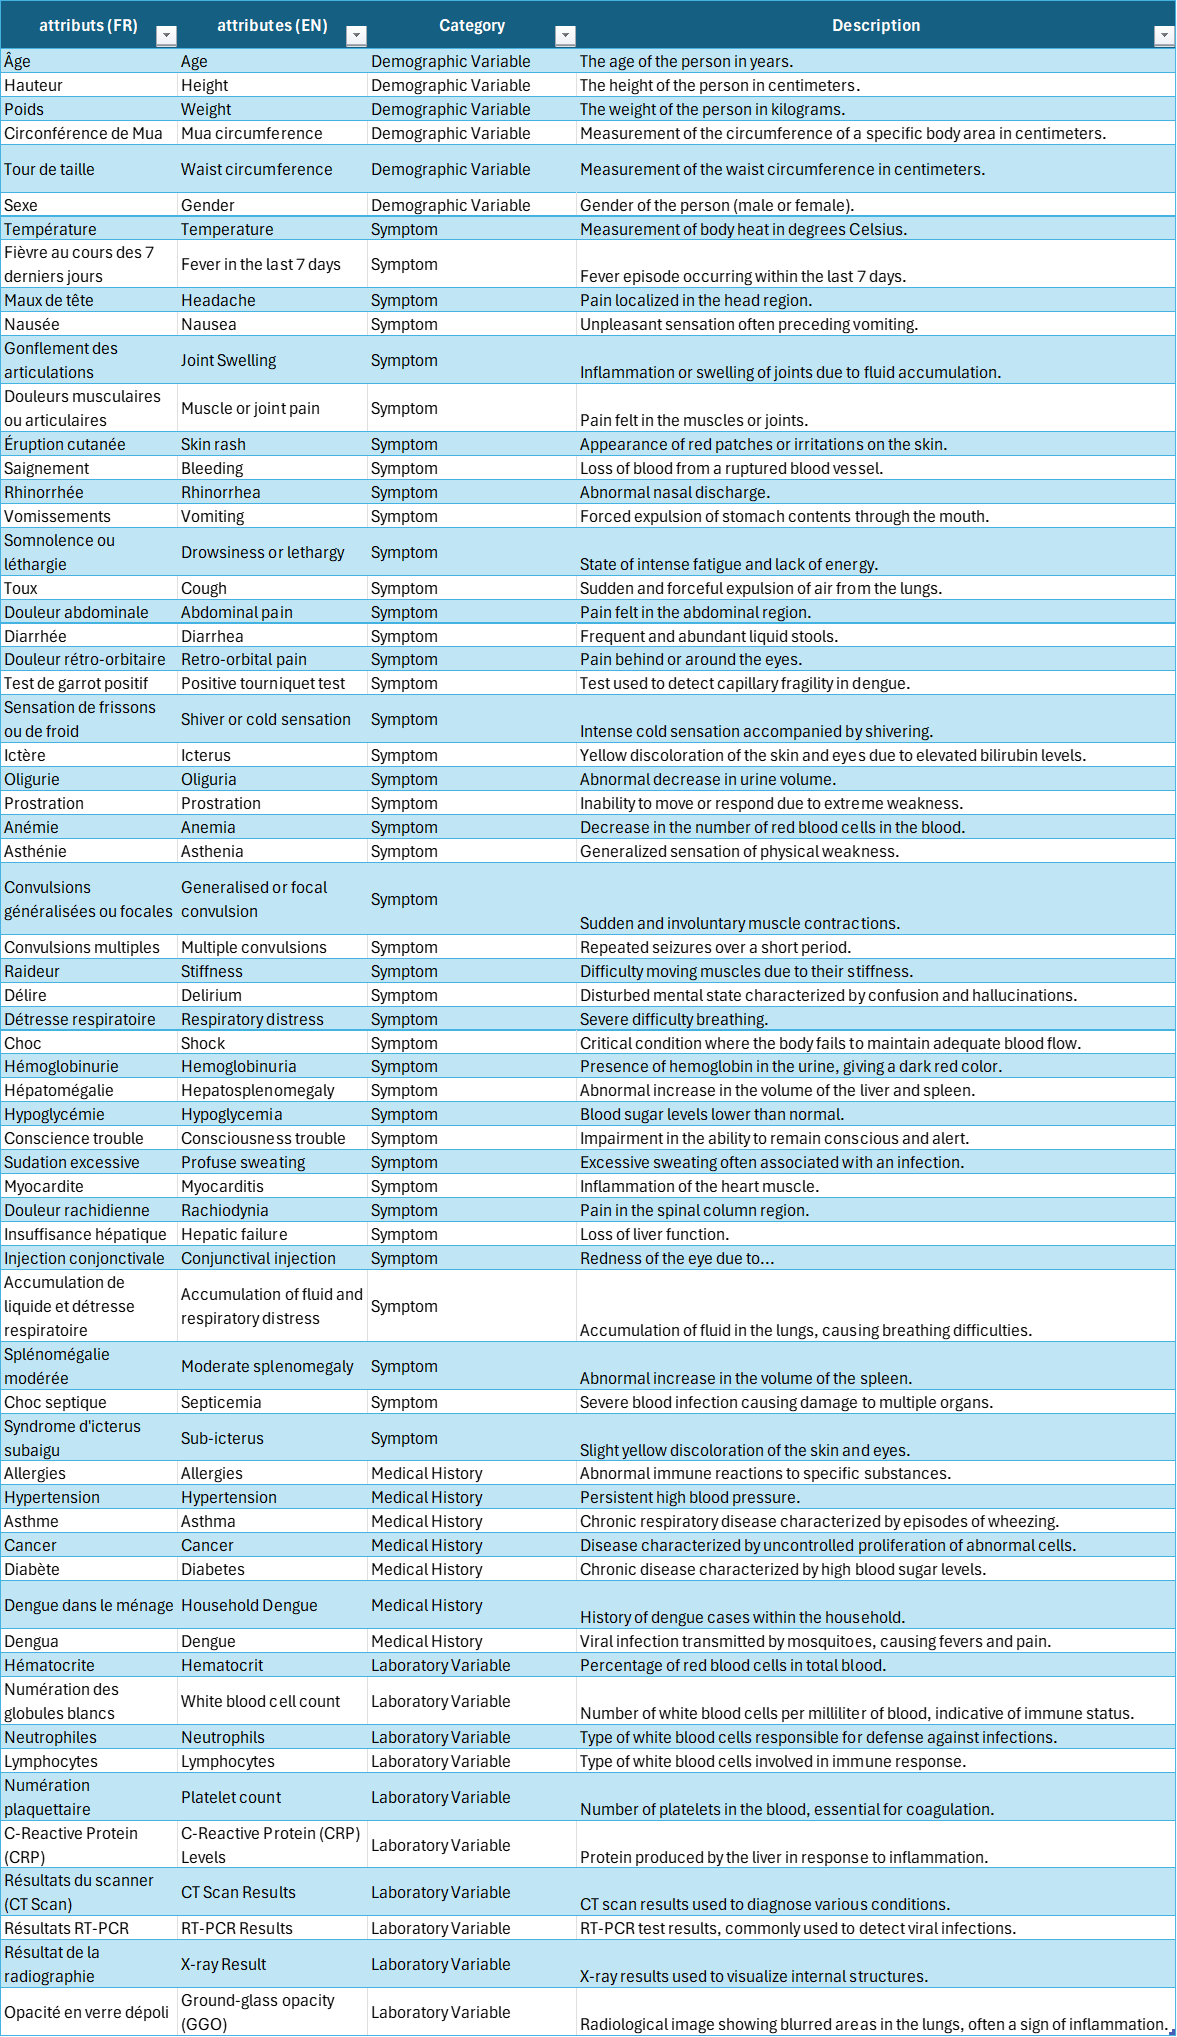

# SECTION 3: List of Requirements


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

# SECTION 4: Data Preprocessing/Cleaning

In [ ]:
vector_df = pd.read_csv('/content/vectordata.csv')
vector_df

,Centre de santé,Genre (Gender),Âge (Age),Poids (Weight),Circonference du bras (Mua circumference),"Haute température.(temperature, Hyperpyrexia)",Fièvre depuis 48 heures(Fever 48 hrs),Fièvre au cours des 7 derniers jours (Fever in the last 7 days),Type de fièvre (Type of Fever),Perte de poids (Loss of Weight),...,Maladies diagnostiquées/Paludisme (Malaria),Maladies diagnostiquées/Dengue,Maladies diagnostiquées/Chikunguya,Maladies diagnostiquées/Fièvre jaune (yellow fever),Maladies diagnostiquées/Fièvre Typhoïde (Thyphoid fever),Maladies diagnostiquées/Zika,Maladies diagnostiquées/Autres maladies diagnostiqué (Others diseases),Maladies diagnostiquées/Option 8,Autres maladies présentées par le patient,_uuid
0,CMA de DO,Femme,18,55.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,df22d899-23a3-4c49-8059-6208c130f57d
1,CMA de DO,Homme,26,120.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,4a7ef2f3-4ff0-4215-8cb5-20ba8c8d4355
2,CMA de DO,Homme,25,63.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,NaN,104f6bc8-f39a-482b-b680-7ac1f8cccc86
3,CMA de DO,Homme,3,12.0,"13,5",OUI,OUI,NON,Récurrente,NON,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,26d7d04a-1a1c-4d4b-b64a-606f968e6d9c
4,CMA de DO,Homme,8,24.0,NaN,OUI,OUI,NON,Récurrente,NON,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,eb694f52-51ff-488d-9beb-2923a572a4cf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,CMA de DAFRA,Femme,9,21.0,NaN,OUI,OUI,NON,Intermittente,NON,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,NaN,1a12efa5-794c-480b-af5d-91499018e2a8
296,CMA de DAFRA,Femme,6,19.0,NaN,OUI,OUI,NON,Intermittente,NON,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,7e41d7b6-b8a6-44d7-8a7a-93debef7b1dd
297,CMA de DAFRA,Femme,9,NaN,NaN,OUI,OUI,NON,Intermittente,NON,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,e14dccf8-7059-488c-ae5b-eefa8e316f93
298,CMA de DAFRA,Homme,7,16.0,NaN,OUI,OUI,NON,Intermittente,NON,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,e47f68b7-83cc-43b9-aff1-7ac31fb61495


In [ ]:
#translation to enhance readability
column_translation = {
    "Centre de santé": "Health Center",
    "Genre (Gender)": "Gender",
    "Âge (Age)": "Age",
    "Poids (Weight)": "Weight",
    "Circonference du bras (Mua circumference)": "Arm Circumference",
    "Haute température.(temperature, Hyperpyrexia)": "High Temperature",
    "Fièvre depuis 48 heures(Fever 48 hrs)": "Fever 48 Hours",
    "Fièvre au cours des 7 derniers jours (Fever in the last 7 days)": "Fever Last 7 Days",
    "Type de fièvre (Type of Fever)": "Fever Type",
    "Perte de poids (Loss of Weight)": "Weight Loss",
    "Maux de tête (headache)": "Headache",
    "Nausée (Nausea)": "Nausea",
    "Vomissement (Vomiting)": "Vomiting",
    "Douleur articulaire (Joint pain)": "Joint Pain",
    "Gonflement des articulations (Joint Swelling)": "Joint Swelling",
    "Douleur musculaire ( Muscle pain)": "Muscle Pain",
    "Douleur Thoracique (Chaist pain)": "Chest Pain",
    "Mal de dos / Douleur rachidienne ( Back pain / Rachiodynia)": "Rachiodynia/Back Pain",
    "Troubles de la conscience (Consciousness trouble)": "Consciousness Trouble",
    "Perte d'appétit ou Anorexie (Loss of appetite or Anorexia)": "Loss of appetite or Anorexia",
    "Éruptions cutanées ou Exanthème (Skin rash or Exanthema)": "Skin rash or Exanthema",
    "Éruption morbilliforme (Morbilliform rash)": "Morbilliform rash",
    "Saignement/ Manifestations hémorragiques (Bleeding)": "Bleeding",
    "Rhinorrhée (Rhinorrhea)": "Rhinorrhea",
    "Somnolence ou léthargie (Drowsiness or lethargy)": "Drowsiness or lethargy",
    "Vertige (Dizzy)": "Dizzy",
    "Inflammation de conjonctivite": "Conjunctivitis",
    "Douleur abdominale (stomac pain)": "Stomach pain",
    "Distension abdominale (Ventre gonflé) (Abdominal Distension (Swelling Stomach)/ Ascites)": "Abdominal Distension (Swelling Stomach)/ Ascites)",
    "Mal de gorge (throat pain)" : "throat pain",
    "Toux (Cough)": "Cough",
    "Diarrhée (Diarrhea)": "Diarrhea",
    "Douleur rétro-orbitrale (Retro-orbital pain)": "Retro-orbital pain",
    "Céphalée (Headache)": "Head ache",
    "Sensation de frissons ou de froid (Shiver or cold sensation)": "Shiver or cold sensation",
    "Mictions fréquentes.(Frequent Urination)": "Frequent Urination",
    "Test TDR": "Rapid Test",
    "Epistaxis ((Bleeding nose)": "Bleeding nose",
    "Goutte épaisse": "Blood smear",
    "Hémoconcentration": "Hemoconcentration",
    "Goût amer dans la gorge (Bitter taste in your Throat)": "Bitter taste in your Throat",
    "Test de garrot positif (Positive tourniquet test)": "Positive tourniquet test",
    "Insuffisance cardiaque ou Myocardite(Heart failure or Myocarditis)": "Heart failure or Myocarditis",
    "Asthme (Astma)": "Asthma",
    "Pâleur cutanéo muqueuse ou Anémie (Mucosal skin pallor or Anemia)": "Pallor or Anemia",
    "Hypoglycémie (Hypoglycemia)": "Hypoglycemia",
    "Paludisme (Malaria)": "Malaria",
    "Drépanocytose": "Sickle Cell Disease",
    "Dengue (Dengua)": "Dengue",
    "Diabète": "Diabetes",
    "Arthrose": "Osteoarthritis",
    "Splénomégalie modérée": "Splenomegaly",
    "Dengue dans le menage (Household Dengue)": "Household Dengue",
    "Maladies diagnostiquées/Dengue": "Diagnosed: Dengue",
    "Maladies diagnostiquées/Fièvre Typhoïde (Thyphoid fever)": "Diagnosed: Typhoid Fever",
    "Maladies diagnostiquées/Zika": "Diagnosed: Zika",
    "Maladies diagnostiquées/Autres maladies diagnostiqué (Others diseases)": "Diagnosed: Other Diseases",
    "Maladies diagnostiquées/Paludisme (Malaria)": "Diagnosed: Malaria",
    "Maladies diagnostiquées/Chikunguya": "Diagnosed: Chikungunya",
    "Maladies diagnostiquées/Fièvre jaune (yellow fever)": "Diagnosed: Yellow Fever",
    "Maladies diagnostiquées/Option 8": "Diagnosed: Other",
    "Autres maladies présentées par le patient": "Other illnesses presented by patient",
    "Maladies diagnostiquées": "Diagnosed Diseases",
    "Fever 48 Hours": "Fever 48 Hours",
    "Fever Last 7 Days": "Fever Last 7 Days",
    "High Temperature": "High Temperature"
}

cleaned_column_translation = {}
for key, value in column_translation.items():
    # Apply the cleaning logic to the key
    cleaned_key = ' '.join(key.split())
    cleaned_key = cleaned_key.replace('Ã©', 'e').replace('Ã¨', 'e').replace('Â°C', 'C').replace('Â±', '').replace('.', '').replace('in', '').replace('-', '').replace('secs', '').replace('mmHg', '').replace('SD', '').replace('IQR', '').replace('beats', '').replace('breaths', '').replace('min', '')
    cleaned_key = cleaned_key.replace('  ', ' ') # Remove double spaces

    # Add the cleaned key and the original value to the new dictionary
    cleaned_column_translation[cleaned_key] = value

column_translation = cleaned_column_translation


# Translate columns
vector_df = vector_df.rename(columns=column_translation)

# Remove non-English characters and unnecessary letters from headers
vector_df.columns = vector_df.columns.str.replace(r'[\(\).,]', '', regex=True).str.strip()

In [ ]:
diagnosis_eng = {
    'Paludisme (Malaria) Dengue': 'Malaria, Dengue',
    'Paludisme (Malaria) Fièvre Typhoïde (Thyphoid fever)': 'Malaria, Typhoid Fever',
    'Paludisme (Malaria)': 'Malaria',
    'Paludisme (Malaria) Chikunguya': 'Chikungunya',
    'Paludisme (Malaria) Fièvre jaune (yellow fever)': 'Yellow Fever',
    'Paludisme (Malaria) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Other Diseases',
    'Paludisme (Malaria) Option 8': 'Malaria, Other Diseases',
    'Paludisme (Malaria) Dengue Autres maladies diagnostiqué (Others diseases)': 'Malaria, Dengue, Other Diseases',
    'Paludisme (Malaria) Fièvre Typhoïde (Thyphoid fever) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Typhoid Fever, Other Diseases',
    'Paludisme (Malaria) Chikunguya Autres maladies diagnostiqué (Others diseases)': 'Malaria, Chikungunya, Other Diseases',
    'Dengue Autres maladies diagnostiqué (Others diseases)': 'Other Diseases, Dengue',
    'Dengue Fièvre jaune (yellow fever)': 'Dengue, Yellow Fever',
    'Paludisme (Malaria) Fièvre jaune (yellow fever) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Yellow Fever, Other Diseases',
    'Fièvre Typhoïde (Thyphoid fever)': 'Typhoid Fever',
    'Paludisme (Malaria) Dengue Fièvre Typhoïde (Thyphoid fever)': 'Malaria, Dengue, Typhoid Fever',
    'Fièvre jaune (yellow fever) Fièvre Typhoïde (Thyphoid fever)': 'Yellow Fever, Typhoid Fever',
    'Paludisme (Malaria) Dengue Fièvre jaune (yellow fever)': 'Malaria, Dengue, Yellow Fever',
    'Dengue Fièvre Typhoïde (Thyphoid fever)': 'Dengue, Typhoid Fever',
    'Autres maladies diagnostiqué (Others diseases)': 'Other Diseases',
    '(Malaria) Dengue': 'Malaria, Dengue'

}

vector_df['Diagnosed Diseases'] = vector_df['Diagnosed Diseases'].replace(diagnosis_eng)

In [ ]:
# Remove features not needed
vector_df.drop(columns=['Health Center', 'Gender','_uuid','Other illnesses presented by patient'], errors='ignore', inplace=True)

# Remove unrelated conditions to vector-borne disease
vector_df.drop(columns=['Rachiodynia/Back Pain', 'Asthma', 'Cancer','Bitter taste in your throat','Diabetes','Osteoarthritis','Heart failure or Myocarditis'], errors='ignore', inplace=True)

In [ ]:
display(vector_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 100 columns):
 #   Column                                                                                           Non-Null Count  Dtype  
---  ------                                                                                           --------------  -----  
 0   Age                                                                                              300 non-null    object 
 1   Weight                                                                                           196 non-null    float64
 2   Arm Circumference                                                                                25 non-null     object 
 3   Haute températuretemperature Hyperpyrexia                                                        299 non-null    object 
 4   Fever 48 Hours                                                                                   297 non-null    object 
 5   Fièvre 

None

In [ ]:
#Remove duplicated columns
vector_df.drop(columns=['Mictions fréquentes. (Frequent Urination)', 'Dengue', 'Household Dengue', 'Head ache', 'Arm Circumference'], errors='ignore', inplace=True)
vector_df.drop(columns=['Pression artérielle moyenne mmHg ± SD / Arterial blood pressure mean mmHg ± SD', 'Température axillaire médiane IQR °C /Axillary temperature median IQR °C', 'Lymphocytes', 'Neutrophiles / Neutrophils'], errors='ignore', inplace=True)

vector_df.shape

(300, 92)

In [ ]:
#Transform categories into binary values
vector_df.replace({'OUI': 1, 'NON': 0}, inplace=True)
vector_df.replace({'Oui': 1, 'Non': 0}, inplace=True)
vector_df.replace({'Récurrente': 1, 'Intermittente': 0}, inplace=True)
vector_df.replace({'Positif': 1, 'Négatif': 0}, inplace=True)

# Replace comma with period in all columns
vector_df = vector_df.replace(',', '.', regex=True, inplace=False)
vector_df.head()

/tmp/ipython-input-9-2104982766.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.replace({'OUI': 1, 'NON': 0}, inplace=True)
/tmp/ipython-input-9-2104982766.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.replace({'Récurrente': 1, 'Intermittente': 0}, inplace=True)
/tmp/ipython-input-9-2104982766.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the futu

,Age,Weight,Haute températuretemperature Hyperpyrexia,Fever 48 Hours,Fièvre au cours des 7 derniers jours Fever in the last 7 days,Fever Type,Weight Loss,Headache,Nausea,Vomissement Vomiting,...,Pneumonie Pneumonia,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Diagnosed: Other
0,18,55.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,26,120.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,25,63.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,Malaria. Typhoid Fever,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,3,12.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8,24.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
import numpy as np
# Impute numerical columns with the median
numerical_cols = vector_df.select_dtypes(include=np.number).columns
for col in numerical_cols:
    if vector_df[col].isnull().any():
        median_val = vector_df[col].median()
        vector_df[col].fillna(median_val, inplace=True)

print("Null percentages after median imputation for numerical columns:")
print(vector_df.isnull().sum()/vector_df.shape[0]*100)

Null percentages after median imputation for numerical columns:
Age                                                              0.0
Weight                                                           0.0
Haute températuretemperature Hyperpyrexia                        0.0
Fever 48 Hours                                                   0.0
Fièvre au cours des 7 derniers jours Fever in the last 7 days    0.0
                                                                ... 
Diagnosed: Yellow Fever                                          0.0
Diagnosed: Typhoid Fever                                         0.0
Diagnosed: Zika                                                  0.0
Diagnosed: Other Diseases                                        0.0
Diagnosed: Other                                                 0.0
Length: 92, dtype: float64


/tmp/ipython-input-10-4001847369.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  vector_df[col].fillna(median_val, inplace=True)


In [ ]:
# Fever Binning
def fever_level(row):
    # Handle potential NaN values by converting to 0 before converting to int
    fever_48 = int(row.get('Fever 48 Hours', 0) or 0)
    fever_7d = int(row.get('Fièvre au cours des 7 derniers jours Fever in the last 7 days', 0) or 0)
    temp = int(row.get('Haute températuretemperature Hyperpyrexia', 0) or 0)
    score = fever_48 + fever_7d + temp
    if score == 0: return 'None'
    elif score == 1: return 'Mild'
    elif score == 2: return 'Moderate'
    else: return 'Severe'

vector_df['Fever_Level'] = vector_df.apply(fever_level, axis=1)
vector_df.drop(columns=[
    'Fever 48 Hours', # Update to translated column name
    'Fièvre au cours des 7 derniers jours Fever in the last 7 days', # Update to translated column name
    'Haute températuretemperature Hyperpyrexia' # Update to translated column name
], inplace=True)

display(vector_df.head())

,Age,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomissement Vomiting,Douleur articulaire Joint pain,Gonflement des articulations Joint Swelling,Douleur musculaire Muscle pain,...,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Diagnosed: Other,Fever_Level
0,18,55.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,Severe
1,26,120.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,Severe
2,25,63.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,Malaria. Typhoid Fever,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,Severe
3,3,12.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Moderate
4,8,24.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Moderate


In [ ]:
# Define the mapping for ordinal encoding
fever_level_mapping = {
    'None': 0,
    'Mild': 1,
    'Moderate': 2,
    'Severe': 3
}
# Convert 'Fever_Level' to ordinal numbers
vector_df['Fever_Level'] = vector_df['Fever_Level'].map(fever_level_mapping)

# Check for NaN values after mapping
print("NaN values in Fever_Level after mapping:", vector_df['Fever_Level'].isnull().sum())

# Optionally, fill NaN values with a default value (e.g., 0)
vector_df['Fever_Level'] = vector_df['Fever_Level'].fillna(0)

# Check the unique values after encoding
print("Unique values in Fever_Level after encoding:", vector_df['Fever_Level'].unique())

NaN values in Fever_Level after mapping: 0
Unique values in Fever_Level after encoding: [3 2 1 0]


In [ ]:
import numpy as np

# Impute the specified columns with the median
cols_to_impute = [
    'Nombre de globules blancs cellules/ML / White blood cell count / WBC count cells/ML',
    'Hematocrite Hematrocrit',
    'Numération plaquettaire Platelet count',
    'Fréquence du pouls battements/m in ± SD/ Pulse rate mean beats/min ± SD - Shock ou Myocarditis',
]

for col in cols_to_impute:
    if col in vector_df.columns:
        # Convert to numeric, coercing errors to NaN using .loc for explicit indexing
        vector_df.loc[:, col] = pd.to_numeric(vector_df[col], errors='coerce')
        if vector_df[col].isnull().any():
            median_val = vector_df[col].median()
            # Impute NaN values using .loc for explicit indexing
            vector_df.loc[:, col].fillna(median_val, inplace=True)
    else:
        print(f"Warning: Column '{col}' not found in the DataFrame.")

print("\nNull percentages after specific column imputation:")
# Check for null percentages only in the specified columns that were found
found_cols_to_impute = [col for col in cols_to_impute if col in vector_df.columns]
if found_cols_to_impute:
    print(vector_df[found_cols_to_impute].isnull().sum()/vector_df[found_cols_to_impute].shape[0]*100)
else:
    print("None of the specified columns were found in the DataFrame.")


Null percentages after specific column imputation:
Nombre de globules blancs cellules/ML / White blood cell count / WBC count cells/ML               0.0
Hematocrite Hematrocrit                                                                           0.0
Numération plaquettaire Platelet count                                                            0.0
Fréquence du pouls battements/m in ± SD/ Pulse rate mean beats/min ± SD - Shock ou Myocarditis    0.0
dtype: float64


/tmp/ipython-input-13-3700107577.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  vector_df.loc[:, col].fillna(median_val, inplace=True)
/tmp/ipython-input-13-3700107577.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.loc[:, col].fillna(median_val, inplace=True)
/tmp/ipython-input-13-37001075

In [ ]:
# Removes noise in age column
vector_df = vector_df[~vector_df['Age'].isin(['15-Dec', '07-Dec'])].reset_index(drop=True)
display(vector_df.shape)

(298, 90)

In [ ]:
scaler = StandardScaler()
vector_df['Weight'] = scaler.fit_transform(vector_df[['Weight']])
vector_df['Nombre de globules blancs cellules/ML / White blood cell count / WBC count cells/ML'] = scaler.fit_transform(vector_df[['Nombre de globules blancs cellules/ML / White blood cell count / WBC count cells/ML']])
vector_df['Fréquence du pouls battements/m in ± SD/ Pulse rate mean beats/min ± SD - Shock ou Myocarditis'] = scaler.fit_transform(vector_df[['Fréquence du pouls battements/m in ± SD/ Pulse rate mean beats/min ± SD - Shock ou Myocarditis']])
vector_df['Numération plaquettaire Platelet count'] = scaler.fit_transform(vector_df[['Numération plaquettaire Platelet count']])
vector_df['Créatinine élevée / Elevated Creatinine'] = scaler.fit_transform(vector_df[['Créatinine élevée / Elevated Creatinine']])

display(vector_df.head())

,Age,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomissement Vomiting,Douleur articulaire Joint pain,Gonflement des articulations Joint Swelling,Douleur musculaire Muscle pain,...,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Diagnosed: Other,Fever_Level
0,18,1.181283,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3
1,26,3.988823,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3
2,25,1.526826,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,Malaria. Typhoid Fever,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,3
3,3,-0.676013,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,8,-0.157698,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


In [ ]:
# Identify columns with all zeros
zero_cols = vector_df.columns[(vector_df == 0).all()]

# Drop the identified columns
vector_df.drop(columns=zero_cols, inplace=True)

display(f"Dropped columns with all zero values: {zero_cols.tolist()}")

"Dropped columns with all zero values: ['Conjunctivitis', 'Rougeur faciale Facial flushing', 'Sudation excessive Profuse sweating', 'Maladie rhumatismale', 'Maladie auto immune', 'Allergies', 'Carences en leucocytes Leucopenia', 'Diagnosed: Chikungunya', 'Diagnosed: Zika', 'Diagnosed: Other']"

In [ ]:
vector_df

,Age,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomissement Vomiting,Douleur articulaire Joint pain,Gonflement des articulations Joint Swelling,Douleur musculaire Muscle pain,...,Hypertension artérielle,Sickle Cell Disease,Pneumonie Pneumonia,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Other Diseases,Fever_Level
0,18,1.181283,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,3
1,26,3.988823,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,Malaria. Dengue,1.0,1.0,0.0,0.0,0.0,3
2,25,1.526826,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,Malaria. Typhoid Fever,1.0,0.0,0.0,1.0,0.0,3
3,3,-0.676013,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,2
4,8,-0.157698,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,9,-0.287276,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,Yellow Fever,1.0,0.0,1.0,0.0,0.0,2
294,6,-0.373662,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,2
295,9,-0.416855,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,2
296,7,-0.503241,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,0.0,0.0,2


# SECTION 5: Exploratory Data Analysis


In [ ]:
vector_df.shape

(298, 80)

In [ ]:
vector_df.describe()

,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomissement Vomiting,Douleur articulaire Joint pain,Gonflement des articulations Joint Swelling,Douleur musculaire Muscle pain,Douleur Thoracique Chaist pain,...,ALAT / ASAT élevés / Elevated ALAT / Elevated ASAT,Hypertension artérielle,Sickle Cell Disease,Pneumonie Pneumonia,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Other Diseases,Fever_Level
count,2.980000e+02,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,...,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000,298.000000
mean,9.537486e-17,0.550336,0.073826,0.785235,0.439597,0.570470,0.456376,0.010067,0.557047,0.063758,...,0.093960,0.057047,0.016779,0.057047,0.902685,0.187919,0.040268,0.097315,0.328859,1.812081
std,1.001682e+00,0.498297,0.261927,0.411350,0.497173,0.495842,0.498931,0.099997,0.497571,0.244733,...,0.292263,0.232322,0.128657,0.232322,0.296885,0.391305,0.196919,0.296885,0.470589,0.794502
min,-1.107942e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-5.896268e-01,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,-4.168552e-01,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,1.507404e-02,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,2.000000
max,4.463945e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [ ]:
# Detect null and present them as percentages
null_percentages = vector_df.isnull().sum()/vector_df.shape[0]*100
null_percentages = null_percentages.sort_values(ascending=False)
if null_percentages.equals(0):
  print("Null percentages: ")
else:
  print("Null values not found.")

Null values not found.


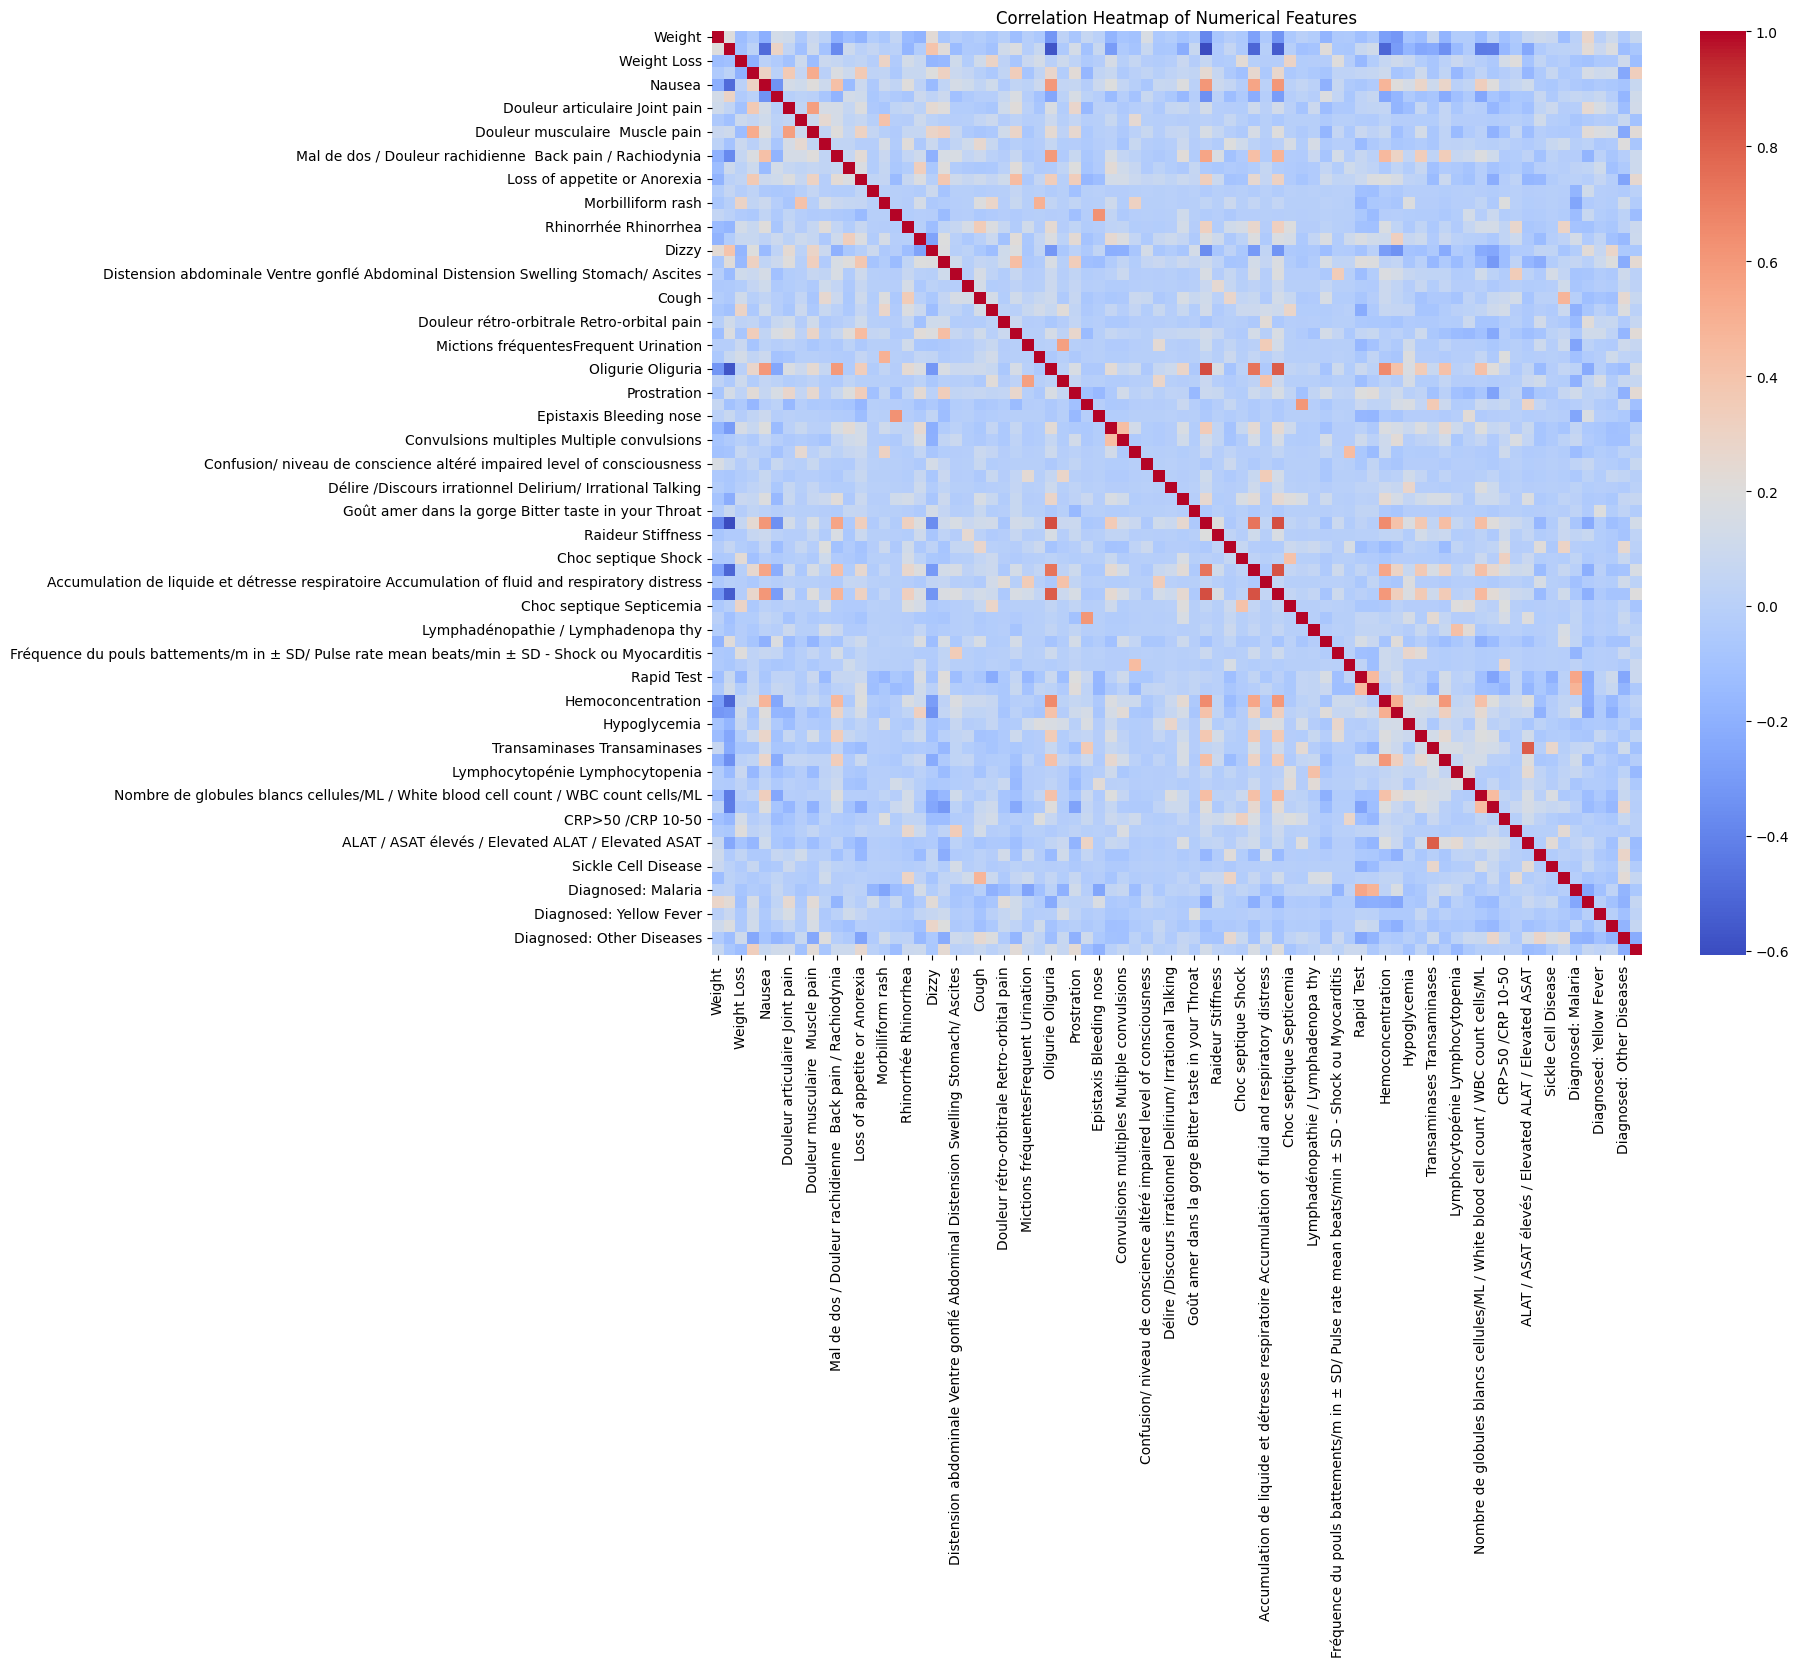

In [ ]:
# Generates heatmap

import matplotlib.pyplot as plt
import numpy as np
# Selecting numerical features for the heatmap
numerical_features = vector_df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = numerical_features.corr()

# Create the heatmap
plt.figure(figsize=(15, 12))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [ ]:
# Function to identify columns with high correlation
def identify_high_correlation_columns(df, threshold=0.8):
  """    threshold: The correlation threshold (default is 0.8).
  """
  correlation_matrix = df.corr()
  high_corr_pairs = []
  for i in range(len(correlation_matrix.columns)):
    for j in range(i):
      if abs(correlation_matrix.iloc[i, j]) >= threshold:
        col1 = correlation_matrix.columns[i]
        col2 = correlation_matrix.columns[j]
        high_corr_pairs.append((col1, col2))
  return high_corr_pairs

# Select only numerical columns before calculating correlation
numerical_df = vector_df.select_dtypes(include=np.number)

# Identify columns with high correlation (adjust threshold as needed)
high_correlation_columns = identify_high_correlation_columns(numerical_df, threshold=0.8)

print("Columns with a correlation of 0.8 or higher:")
for col1, col2 in high_correlation_columns:
  print(f"- {col1} and {col2}")


Columns with a correlation of 0.8 or higher:
- Positive tourniquet test and Oligurie Oliguria
- Splenomegaly and Oligurie Oliguria
- Splenomegaly and Positive tourniquet test
- Splenomegaly and Hépatomégalie Hepatomegaly
- ALAT / ASAT élevés / Elevated ALAT / Elevated ASAT and Transaminases Transaminases


In [ ]:
#Drop features with high-correlation except from mentioned by medical professional
vector_df.drop(columns=['Transaminases Transaminases', 'Hépatomégalie Hepatomegaly','Splenomegaly','Oligurie Oliguria'], errors='ignore', inplace=True)
vector_df.shape

(298, 76)

/tmp/ipython-input-24-3608640700.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-24-3608640700.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-24-3608640700.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-24-3608640700.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variab

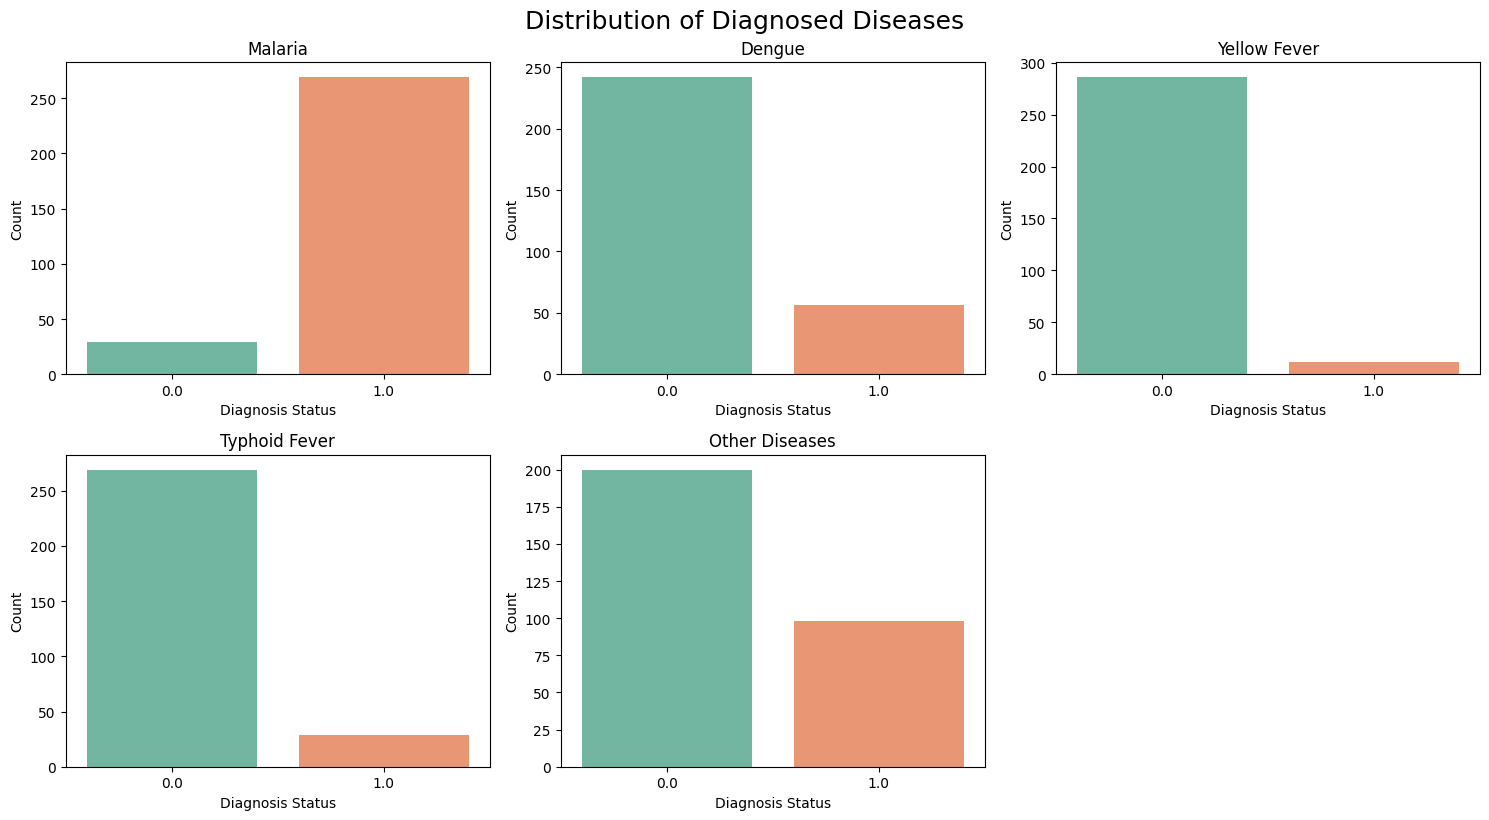

In [ ]:
# Identify diagnosis columns
diagnosed_cols = [col for col in vector_df.columns if col.startswith('Diagnosed:')]

# Set up the subplot grid (adjust columns/rows as needed)
n_cols = 3
n_rows = (len(diagnosed_cols) + n_cols - 1) // n_cols
plt.figure(figsize=(5 * n_cols, 4 * n_rows))

# Loop and plot each column
for i, col in enumerate(diagnosed_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(data=vector_df, x=col, palette="Set2")
    plt.title(col.replace("Diagnosed:", "").strip())
    plt.xlabel('Diagnosis Status')
    plt.ylabel('Count')

plt.tight_layout()
plt.suptitle('Distribution of Diagnosed Diseases', fontsize=18, y=1.02)
plt.show()


In [ ]:
# Drop rows where 'Diagnosed Diseases' contains 'Yellow Fever', 'Typhoid Fever', or 'Other Diseases'
vector_df = vector_df[~vector_df['Diagnosed Diseases'].str.contains('Yellow Fever|Typhoid Fever|Nan', na=False)].copy()

vector_df.drop(columns=['Diagnosed: Yellow Fever', 'Diagnosed: Typhoid Fever'], errors='ignore', inplace=True)

# Display the first few rows of the updated DataFrame to verify
display(vector_df.head())

# Display the shape of the updated DataFrame to see how many rows were dropped
print(f"New shape of the DataFrame after dropping rows: {vector_df.shape}")

,Age,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomissement Vomiting,Douleur articulaire Joint pain,Gonflement des articulations Joint Swelling,Douleur musculaire Muscle pain,...,Créatinine élevée / Elevated Creatinine,ALAT / ASAT élevés / Elevated ALAT / Elevated ASAT,Hypertension artérielle,Sickle Cell Disease,Pneumonie Pneumonia,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Other Diseases,Fever_Level
0,18,1.181283,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,-0.056921,0.0,0.0,0.0,0.0,Malaria. Dengue,1.0,1.0,0.0,3
1,26,3.988823,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,-0.061066,0.0,0.0,0.0,0.0,Malaria. Dengue,1.0,1.0,0.0,3
3,3,-0.676013,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,-0.069601,0.0,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,2
4,8,-0.157698,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,-0.061554,0.0,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,2
5,6,-0.416855,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,...,-0.061066,0.0,0.0,0.0,0.0,Malaria,1.0,0.0,0.0,2


New shape of the DataFrame after dropping rows: (258, 74)


KeyboardInterrupt: 

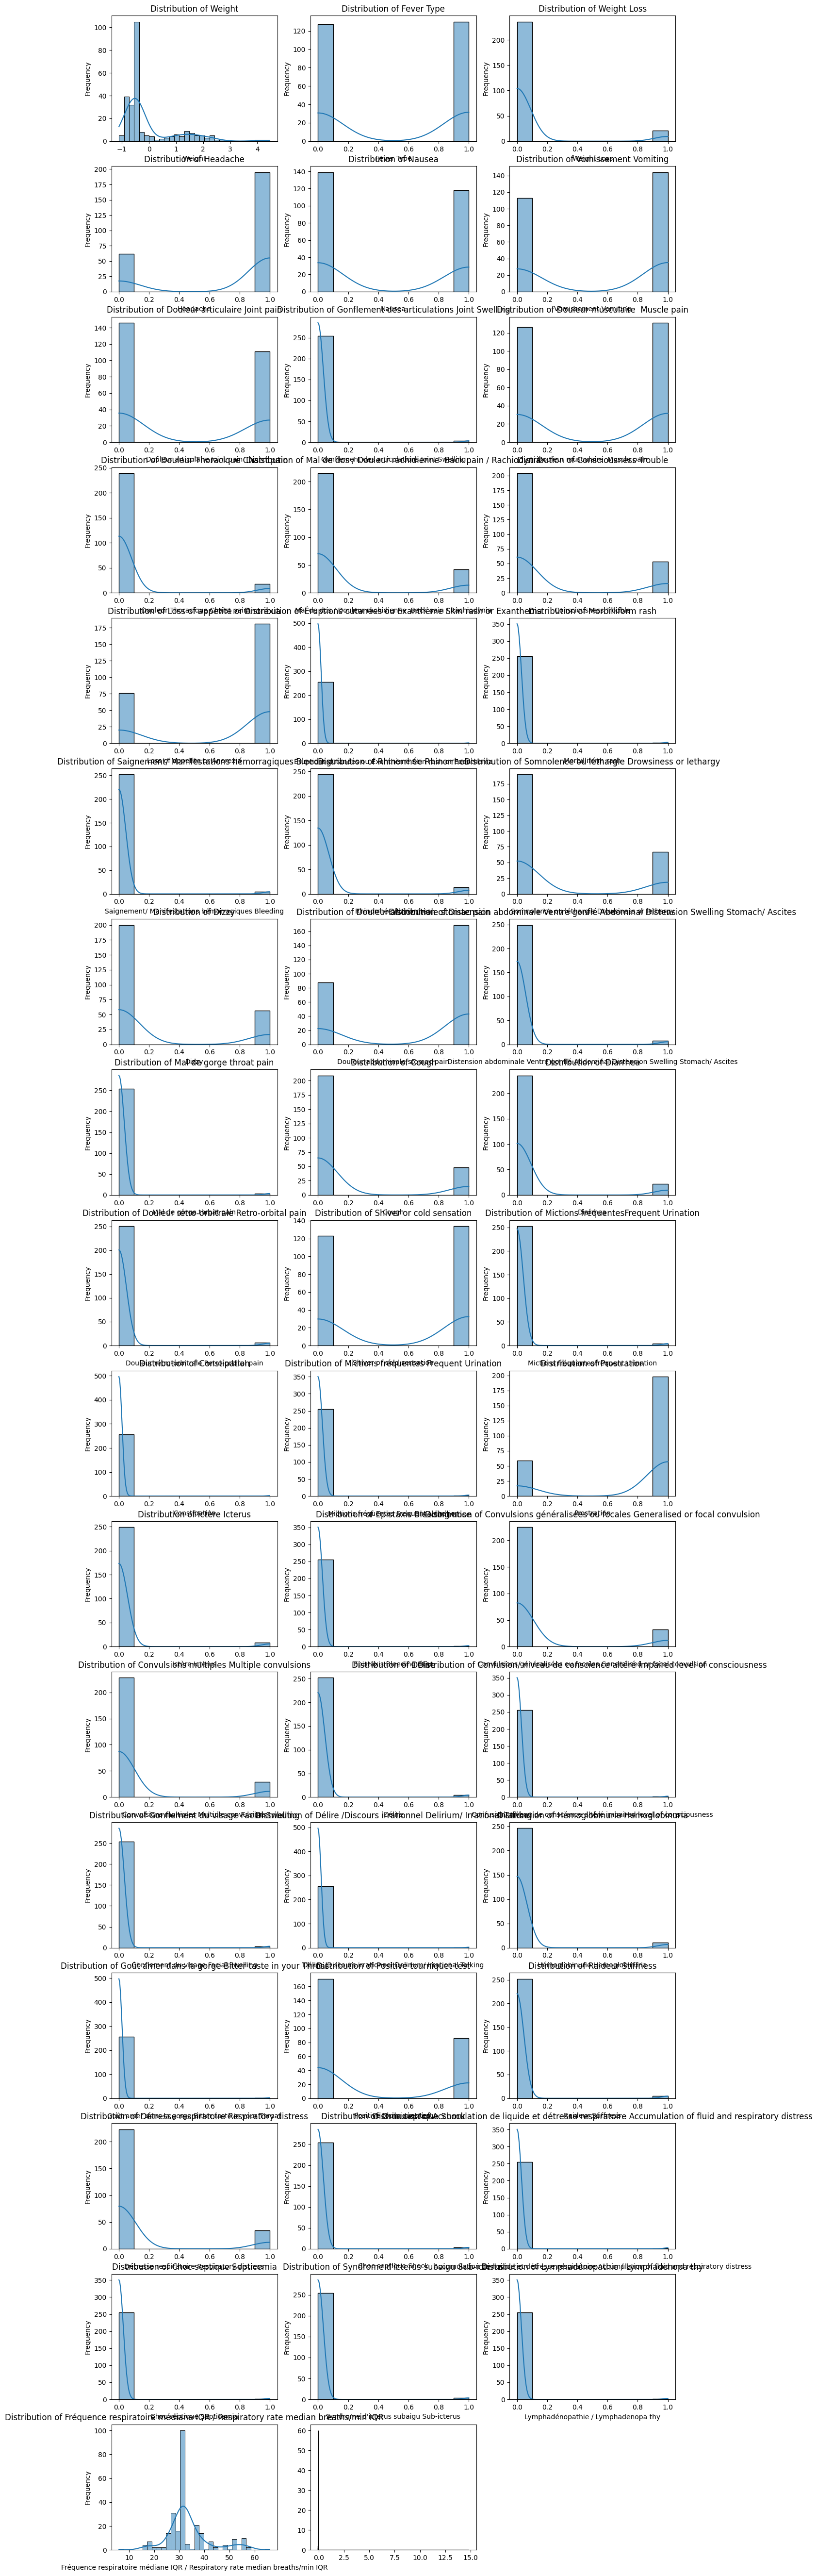

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Plot histogram for numerical columns
numerical_cols = vector_df.select_dtypes(include=np.number).columns
n_cols = 3  # Number of columns in the subplot grid
n_rows = (len(numerical_cols) + n_cols - 1) // n_cols  # Calculate required rows

plt.figure(figsize=(5 * n_cols, 4 * n_rows)) # Adjust figure size based on grid

for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, n_cols, i + 1) # Select the appropriate subplot
    sns.histplot(data=vector_df, x=col, kde=True) # Create the histogram with KDE
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout() # Adjust layout to prevent overlapping
plt.suptitle('Histograms of Numerical Features', fontsize=18, y=1.02) # Add a main title
plt.show()

# SECTION 6: Initial Model Training

MULTINOMIAL LOGISTIC REGRESSION: This model is chosen for its ability to classify categories with more than two classes, beneficial for estimation and interpretation, which are strong characteristics for predictive situations

In [ ]:
excluded_diagnoses = [
    'Diagnosed: Typhoid Fever', 'Diagnosed: Zika',
    'Diagnosed: Yellow Fever', 'Diagnosed: Other Diseases'
]
diagnosed_cols = [col for col in vector_df.columns if col.startswith('Diagnosed:') and col not in excluded_diagnoses]

# Create diagnosis category
def get_diagnosis_category(row):
    diagnoses = [col.replace('Diagnosed: ', '') for col in diagnosed_cols if row[col] == 1.0]
    return ', '.join(sorted(diagnoses)) if diagnoses else 'No Diagnosis'

vector_df['Primary_Diagnosis_Category'] = vector_df.apply(get_diagnosis_category, axis=1)

# Encode category
label_encoder = LabelEncoder()
vector_df['Primary_Diagnosis_Encoded'] = label_encoder.fit_transform(vector_df['Primary_Diagnosis_Category'])

# Prepare features and target
drop_cols = diagnosed_cols + ['Primary_Diagnosis_Category', 'Primary_Diagnosis_Encoded', 'Diagnosed Diseases']
X = vector_df.drop(columns=drop_cols, errors='ignore')
y = vector_df['Primary_Diagnosis_Encoded']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Multinomial logistic regression
model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, class_weight='balanced')
model.fit(X_train_smote, y_train_smote)


In [ ]:
y_pred = model.predict(X_test)
print("Classification Report Initial Model:\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Training accuracy
train_accuracy = accuracy_score(y_train_smote, model.predict(X_train_smote))
print(f"Training Accuracy: {train_accuracy:.4f}")

# Test accuracy
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

# SECTION 7: Error Analysis

In [ ]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Hyperparameter Tuning

In [ ]:
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs', 'saga'],
    'max_iter': [1000, 2000]
}

grid_search = GridSearchCV(
    LogisticRegression(multi_class='multinomial', penalty='l2'),
    param_grid,
    scoring='balanced_accuracy',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_smote, y_train_smote)

# Best model
best_model = grid_search.best_estimator_

# Evaluate on test set
y_pred_best = best_model.predict(X_test)

print("Best Hyperparameters:", grid_search.best_params_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("Classification Report Tuned Model:\n", classification_report(y_test, y_pred_best, target_names=label_encoder.classes_))

# Training accuracy
train_accuracy = accuracy_score(y_train_smote, model.predict(X_train_smote))
print(f"Training Accuracy: {train_accuracy:.4f}")

# Test accuracy
test_accuracy = accuracy_score(y_test, y_pred_best)
print(f"Test Accuracy: {test_accuracy:.4f}")

In [ ]:
labels = ['Before Tuning', 'After Tuning']
f1_scores = [0.6731, grid_search.best_score_]  # Adjust with your actual scores

plt.bar(labels, f1_scores, color=['gray', 'green'])
plt.ylabel("Weighted F1 Score (CV)")
plt.title("Model Performance Before vs After Hyperparameter Tuning")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix (Tuned Model)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# REFERENCES

AI DISCLOSURE: Tools used --> chatgpt, gemini

**prompt: best approaches for imbalanced data sets multinomial logistic regression**

Class Weighting
Use class_weight='balanced' in LogisticRegression to automatically adjust weights inversely proportional to class frequencies

SMOTE (Synthetic Minority Over-sampling Technique)
Apply SMOTE only on training data to synthetically generate samples for minority classes.

Stratified Sampling in Train/Test Split
Always use stratify=y when splitting to maintain class proportions

Don’t use accuracy alone (it favors majority classes). Use:

f1_macro: treats all classes equally

f1_weighted: weighted average based on support

confusion_matrix: to inspect misclassification trends

**prompt: methods of hypertuning an imbalanced dataser**
f1_macro, recall_macro scoring	Balances evaluation across classes
tratified K-Folds	Maintains class distribution during cross-validation
class_weight='balanced'	Reduces majority class dominance
SMOTE + Pipeline	Augments minority class samples in training folds
GridSearchCV or RandomizedSearchCV	Systematic or efficient tuning